In [1]:
with open(r"C:\Users\arvar\Downloads\general_text_v2.txt", 'r', encoding='utf-8') as f:
    text = f.read()

In [2]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

In [3]:

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string


In [4]:

# hyperparameters
batch_size = 64 # how many independent sequences will we process in parallel?
block_size = 256 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 250
learning_rate = 3e-4
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_emb=384 
n_head=6
n_layer=6
dropout=0.2
# ------------

torch.manual_seed(1337)


# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]


In [5]:
#this is the function block

In [6]:

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y


In [7]:
class head(nn.Module):
    def __init__(self,head_size):
        super().__init__()
        self.key=nn.Linear(n_emb,head_size)
        self.query=nn.Linear(n_emb,head_size)
        self.val=nn.Linear(n_emb,head_size)
        self.drop=nn.Dropout(dropout)
        self.register_buffer('tril',torch.tril(torch.ones((block_size,block_size))))
    def forward(self,x):
            b,t,c=x.shape
            k=self.key(x)
            q=self.query(x)
            v=self.val(x)
            wei=q@k.transpose(-2,-1) *c**-0.5
            wei=wei.masked_fill(self.tril[:t,:t]==0,float('-inf')) 
            wei=F.softmax(wei,dim=-1)
            wei=self.drop(wei)
            out=wei@v
            return out

class multiheads(nn.Module):
    def __init__(self,num_heads,head_size):
        super().__init__()
        self.heads=nn.ModuleList([head(head_size) for _ in range(num_heads)])
        self.proj=nn.Linear(n_emb,n_emb)
        self.drop=nn.Dropout(dropout)
    def forward(self,x):
        out=torch.cat([h(x) for h in self.heads],dim=-1)
        out=self.proj(out)
        out=self.drop(out)
        return out



In [8]:
class FFn(nn.Module):
    def __init__(self,n_emb):
        super().__init__()
        self.net=nn.Sequential( 
            nn.Linear(n_emb,4*n_emb),
            nn.ReLU(),
            nn.Linear(4*n_emb,n_emb),
            nn.Dropout(dropout),
                              )
    def forward(self,x):
        return self.net(x)

In [9]:
class block(nn.Module):
    def __init__(self,n_emb,n_head):
        super().__init__()
        head_size=n_emb//n_head
        self.sa=multiheads(n_head,head_size)
        self.ffwn=FFn(n_emb)
        self.ln1=nn.LayerNorm(n_emb)
        self.ln2=nn.LayerNorm(n_emb)
    def forward(self,x):
        x=x+self.sa(self.ln1(x))
        x=x+self.ffwn(self.ln2(x))
        
        return x


In [10]:

# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_emb)
        self.pos_embedding_table=nn.Embedding(block_size,n_emb)
        # self.sa_heads=multiheads(4,n_emb//4)
        # self.ffwn=FFn(n_emb)
        self.blocks=nn.Sequential(*[block(n_emb,n_head=n_head) for _ in range(n_layer)])
        self.ln_f=nn.LayerNorm(n_emb)
        self.lm_head=nn.Linear(n_emb,vocab_size)
        

    def forward(self, idx, targets=None):

        B,T=idx.shape
        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb=self.pos_embedding_table(torch.arange(T,device=device))
        x=tok_emb+pos_emb
        # x=self.sa_heads(x)
        # x=self.ffwn(x)
        x=self.blocks(x)
        x=self.ln_f(x)
        logits=self.lm_head(x)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            con_idx=idx[:,-block_size:]
            # get the predictions
            logits, loss = self(con_idx)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)



In [14]:

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
steps_logged = []

best_val_loss = float('inf')
for iter in range(max_iters):
    if iter % eval_interval == 0:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        train_losses.append(losses['train'].item())
        val_losses.append(losses['val'].item())
        steps_logged.append(iter)
        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), 'best_model.pt')

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
losses = estimate_loss()
train_losses.append(losses['train'].item())
val_losses.append(losses['val'].item())
steps_logged.append(iter)
print(f"Final loss after \n step {max_iters}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

# generate from the model
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=500)[0].tolist()))

step 0: train loss 4.4363, val loss 4.4427
Final loss after 
 step 5000: train loss 1.8899, val loss 1.8959

Ez* charrarne to in this evow was ssed. Wity recVe no whard. Did the thit gle
owaht com in. R"Hes sin, and are here een heis haver.

"I not the, spe sto saies she empieer, It suce she maree axpused-in arels:

"I ashe, held the he rexe ardingabls one his agn indine you
ffreltet or fr. Fir shis, coutrd epeace ther, shad thiren bjeieng

splet, ad a to halkey forsam, and ore at_ a to of ithedey. Elinnet til to the
ean nectiome My wisss, an andered sour be, comaf the thas pipincthelffior
hers ray wic


In [15]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=1000)[0].tolist()))


aund deatuse pen o sur owill litt y hen ajuch be murne helm; bot
bout tout at thim _thar as you thing ink, that but wout, how thow fere thow?"

"5light to youre had mis eesied had nos foins hominher's inde
had, you ad het macous. The ay wayblou lden!"

"Nein a ifuraf  chis tour iswe cam of norif ink, anu a a mackhe bat spy
acref cos. Burschilfough ardavect, to Chauld that in to buchtourly her off thrCothinh
woulld, for on in om af. The such on thing oe sand. An Tould
to go thane woththeit ingy unenth wis parecctelas wereatssed hingy
tisqugs tt; whous frehe dee the Fiake atim. And ha, wer was do to the
withey gis told to hin lith o wothiline, E? I aprrevibet come sthoomiat,
he sac and prerienged, and, at buf he suene you as teapy alle to inthive.


I Loncken Winlit Janns buttis the ir aurs-lef and, Bit ongle af an_ geneceann
ots, to the gnd Whe wass ue andd thet reatte ont on twis he evimer o then Morr.

"Bedutteen I the le spugertte 
she vearswis, with I at lan cre to yout."

"Ye lual

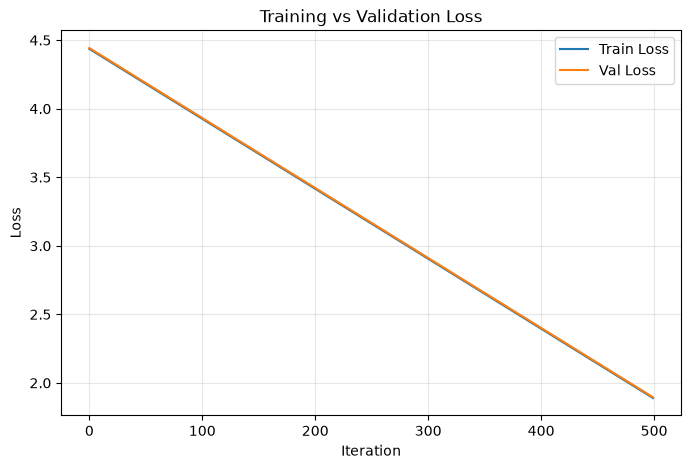

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(steps_logged, train_losses, label='Train Loss')
plt.plot(steps_logged, val_losses, label='Val Loss',linestyle='dotted')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()


In [18]:
# torch.save(m.state_dict(),"gpt_weights.pth")


[4.436294078826904, 1.8899140357971191]
[4.442685127258301, 1.895888090133667]


[0, 499]

In [ ]:
# step 0: train loss 4.3385, val loss 4.3295
# step 500: train loss 1.8464, val loss 1.9767
# step 1000: train loss 1.4760, val loss 1.6779
# step 1500: train loss 1.3261, val loss 1.5647
# step 2000: train loss 1.2421, val loss 1.5167
# step 2500: train loss 1.1819, val loss 1.4940
# step 3000: train loss 1.1253, val loss 1.4836
# step 3500: train loss 1.0783, val loss 1.4916
# step 4000: train loss 1.0300, val loss 1.5097
# step 4500: train loss 0.9839, val loss 1.5197

In [13]:
model = BigramLanguageModel()
model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)
# only if you saved a scheduler_state_dict:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=3000, eta_min=1e-5)

checkpoint = torch.load('checkpoint.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
if 'scheduler_state_dict' in checkpoint:
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
start_iter = checkpoint['iter'] + 1
best_val_loss = checkpoint['best_val_loss']
print(f"Resumed from iter {start_iter - 1}, best_val_loss so far: {best_val_loss:.4f}")


Resumed from iter 10750, best_val_loss so far: 1.1709


In [14]:
model.train()
print(f"Resumed from iter {start_iter - 1}, best_val_loss so far: {best_val_loss:.4f}")

extra_iters = 3000
train_losses=[]
val_losses=[]
steps_logged=[]
for iter in range(start_iter, start_iter + extra_iters):
    if iter % eval_interval == 0:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        train_losses.append(losses['train'].item())
        val_losses.append(losses['val'].item())
        steps_logged.append(iter)
        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save({
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                # 'scheduler_state_dict': scheduler.state_dict(),
                'iter': iter,
                'best_val_loss': best_val_loss,
            }, 'checkpoint.pt')

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    scheduler.step()
    


Resumed from iter 10750, best_val_loss so far: 1.1709
step 11000: train loss 1.2250, val loss 1.1709
step 11250: train loss 1.2234, val loss 1.1707
step 11500: train loss 1.2236, val loss 1.1699
step 11750: train loss 1.2229, val loss 1.1724
step 12000: train loss 1.2213, val loss 1.1701
step 12250: train loss 1.2207, val loss 1.1681
step 12500: train loss 1.2213, val loss 1.1667
step 12750: train loss 1.2183, val loss 1.1696
step 13000: train loss 1.2204, val loss 1.1672
step 13250: train loss 1.2195, val loss 1.1687
step 13500: train loss 1.2174, val loss 1.1663
step 13750: train loss 1.2172, val loss 1.1653


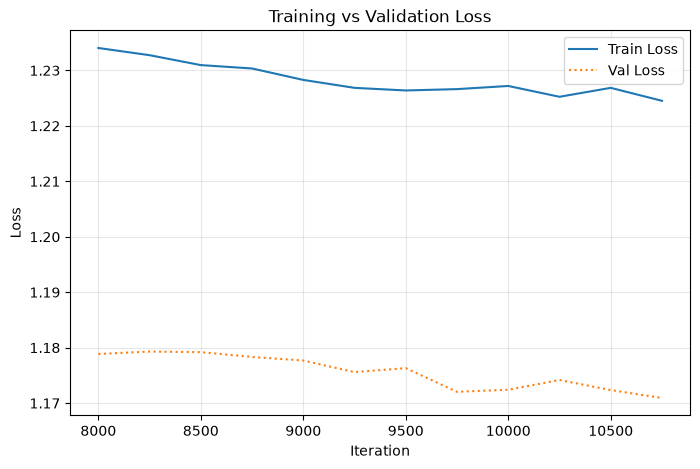

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(steps_logged, train_losses, label='Train Loss')
plt.plot(steps_logged, val_losses, label='Val Loss',linestyle='dotted')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()


In [15]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=1000)[0].tolist()))

	
After you dret, and I spent try to chose you?”

“Yes!”

“I tell you, touch I have handed it wearily; we counter.”

“What’s young afternoon by it come. If The passed the Nativewhale; and
Caria would my heart is convey sheard out of the crowd; you will do
are no done,—began it.”

“I have a great friendless friends, but your face, lake a vicid!” “I am a
calling in
the house; much?” said I. “I should take it a little assure of yony unce?

Keep,
I entermin’t bed. Fourish the malicable caph, and see my gain in my prove
lifeness, Pip’s.”

“What did? I was always interches were all finish the saileasm in
these abhoritors, it out. There’s something twice-country; I say, you’ve
go use.”

“I think you are lost commentions, but you not obey find your jeal
tears. In those days, all the world man. Elizabeth, they seemed, which I
don’t like your own inconsign even in your castle.”

Having de not more for go sharp hear me at these.

Much Herbert’s own blue scering furnished, why Our argition of keel